In [85]:
# น าเข้าไลบรารี Pandas ส าหรับจัดการข้อมูลแบบตาราง
import pandas as pd

# น าเข้าไลบรารี NumPy ส าหรับช่วยประมวลผลข้อมูล
import numpy as np

In [86]:
# read_excel() อ่านข้อมูลจากไฟล์ Excel มาเก็บเป็น DataFrame ส่วน head() แสดง 5 แถวแรก
df = pd.read_excel("marketing.xlsx")
df.head()

,customer_id,age,monthly_income,months_customer,avg_monthly_spend,orders_6m,website_visits_month,discount_usage_percent,membership_tier,contact_channel,campaign_response
0,CU00813,55.0,27209.3,24.0,7748.1,17.0,6.0,0.0,Silver,SMS,1
1,CU00364,43.0,28481.1,76.0,6038.5,20.0,6.0,15.0,Basic,App,0
2,CU00819,40.0,46179.1,27.0,3522.2,8.0,28.0,54.7,Silver,Email,0
3,CU00836,53.0,59191.8,14.0,4384.5,10.0,18.0,22.8,Basic,SMS,0
4,CU00430,33.0,28402.6,37.0,1337.3,0.0,7.0,48.4,Basic,SMS,0


## 1. Problem Understanding และ Data Understanding

โจทย์นี้เป็นงาน **Classification** เพื่อทำนาย `campaign_response` โดย `1` หมายถึงตอบรับแคมเปญ และ `0` หมายถึงไม่ตอบรับ ข้อมูลต้นฉบับมี 1,062 records และ 11 คอลัมน์ เป้าหมายคือเปรียบเทียบโมเดลอย่างน้อย 2 แบบและอธิบายผลด้วย Accuracy, Precision, Recall, F1-score และ Confusion Matrix

In [87]:
# shape แสดงจำนวนแถวและคอลัมน์ของ DataFrame
print("จำนวนแถวและคอลัมน์:", df.shape)

# เว้นบรรทัดและแสดงหัวข้อจำนวนค่าว่าง
print("\nจำนวนค่าว่าง")

# isnull() ระบุตำแหน่งค่าว่าง และ sum() นับจำนวนค่าว่างแยกตามคอลัมน์
print(df.isnull().sum())
# เว้นบรรทัดและแสดงหัวข้อจำนวนขอ้มูลซ้า
print("\nจำนวนขอ้มูลซ้า ")
# duplicated() ระบุแถวที่ซ้ำทั้งแถว และ sum() นับจำนวนแถวดังกล่าว
print(df.duplicated().sum())

# info() สรุปชื่อคอลัมน์ ชนิดข้อมูล จำนวนค่าที่ไม่ว่าง และการใช้หน่วยความจำ
df.info()

จำนวนแถวและคอลัมน์: (1062, 11)

จำนวนค่าว่าง
customer_id               0
age                       1
monthly_income            3
months_customer           5
avg_monthly_spend         1
orders_6m                 5
website_visits_month      2
discount_usage_percent    0
membership_tier           3
contact_channel           8
campaign_response         0
dtype: int64

จำนวนขอ้มูลซ้า 
12
<class 'pandas.DataFrame'>
RangeIndex: 1062 entries, 0 to 1061
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             1062 non-null   str    
 1   age                     1061 non-null   float64
 2   monthly_income          1059 non-null   float64
 3   months_customer         1057 non-null   float64
 4   avg_monthly_spend       1061 non-null   float64
 5   orders_6m               1057 non-null   float64
 6   website_visits_month    1060 non-null   float64
 7   discount_usage_percent  1062 non-nul

In [88]:
# len() บันทึกจำนวนแถวก่อนทำความสะอาด
rows_before = len(df)
# drop_duplicates() เก็บแถวแรกของข้อมูลที่ซ้ำกัน; copy() สร้าง DataFrame สำหรับทำงานต่อ
df = df.drop_duplicates(keep="first").copy()
# เก็บข้อมูลก่อนเติมค่าว่างไว้ใช้แบ่งชุดฝึกและชุดทดสอบอย่างถูกต้อง
df_model_raw = df.copy()

# เปรียบเทียบจำนวนแถวก่อนและหลัง แล้วใช้ duplicated().sum() ตรวจแถวซ้ำที่เหลือ
print("จำนวนแถวที่ลบ:", rows_before - len(df))
print("จำนวนแถวหลังลบ:", len(df))
print("จำนวนแถวซ้ำที่เหลือ:", df.duplicated().sum())


จำนวนแถวที่ลบ: 12
จำนวนแถวหลังลบ: 1050
จำนวนแถวซ้ำที่เหลือ: 0


In [89]:
# mean() หาค่าเฉลี่ยอายุ เพื่อนำไปใช้แทนค่าว่าง
age_mean = df["age"].mean()
# fillna() เติมค่าว่าง, round() ปัดเป็นจำนวนเต็ม และ astype() กำหนดชนิดข้อมูลเป็น int64
df["age"] = df["age"].fillna(age_mean).round().astype("int64")

# isna().sum() นับค่าว่าง, min()/max() หาช่วงค่า, dtype แสดงชนิดข้อมูล
print("ค่าว่างที่เหลือ:", df["age"].isna().sum())
print("ช่วงอายุ:", df["age"].min(), "ถึง", df["age"].max())
print("ชนิดข้อมูล:", df["age"].dtype)
# mod(1) ตรวจเศษ, eq(0) เช็กว่าเศษเป็นศูนย์ และ all() ยืนยันว่าทุกค่าเป็นจำนวนเต็ม
print("ทุกค่าเป็นจำนวนเต็ม:", df["age"].mod(1).eq(0).all())


ค่าว่างที่เหลือ: 0
ช่วงอายุ: 20 ถึง 83
ชนิดข้อมูล: int64
ทุกค่าเป็นจำนวนเต็ม: True


In [90]:
# monthly_income = รายได้ของลูกค้าต่อเดือน (ไฟล์ไม่ได้ระบุหน่วยเงิน)
# mean() หาค่าเฉลี่ยรายได้ และ fillna() ใช้ค่าเฉลี่ยแทนข้อมูลที่ว่าง
income_mean = df["monthly_income"].mean()
df["monthly_income"] = df["monthly_income"].fillna(income_mean)

# isna().sum() นับค่าว่าง; round() ปัดค่าที่แสดงให้เหลือ 2 ตำแหน่ง
print("ค่าว่างที่เหลือ:", df["monthly_income"].isna().sum())
print("ค่าเฉลี่ยที่ใช้เติม:", round(income_mean, 2))
print("ช่วงรายได้:", round(df["monthly_income"].min(), 2), "ถึง", round(df["monthly_income"].max(), 2))
print("ชนิดข้อมูล:", df["monthly_income"].dtype)


ค่าว่างที่เหลือ: 0
ค่าเฉลี่ยที่ใช้เติม: 38679.25
ช่วงรายได้: 12000.0 ถึง 90212.2
ชนิดข้อมูล: float64


In [91]:
# months_customer = จำนวนเดือนที่เป็นลูกค้า
# mean() หาค่าเฉลี่ยจำนวนเดือน เพื่อเติมค่าว่าง
months_mean = df["months_customer"].mean()
# fillna() เติมค่าเฉลี่ย, round() ปัดเป็นจำนวนเต็ม และ astype() แปลงเป็น int64
df["months_customer"] = (
    df["months_customer"].fillna(months_mean).round().astype("int64")
)

# ตรวจค่าว่าง จำนวนเดือนต่ำสุด/สูงสุด ชนิดข้อมูล และยืนยันว่าค่าทั้งหมดเป็นจำนวนเต็ม
print("ค่าว่างที่เหลือ:", df["months_customer"].isna().sum())
print("ค่าเฉลี่ยที่ใช้เติม:", round(months_mean, 2))
print("ช่วงจำนวนเดือน:", df["months_customer"].min(), "ถึง", df["months_customer"].max())
print("ชนิดข้อมูล:", df["months_customer"].dtype)
print("ทุกค่าเป็นจำนวนเต็ม:", df["months_customer"].mod(1).eq(0).all())

ค่าว่างที่เหลือ: 0
ค่าเฉลี่ยที่ใช้เติม: 42.66
ช่วงจำนวนเดือน: 1 ถึง 140
ชนิดข้อมูล: int64
ทุกค่าเป็นจำนวนเต็ม: True


In [92]:
# avg_monthly_spend = ยอดใช้จ่ายเฉลี่ยต่อเดือน (หน่วย: บาท)
# mean() คำนวณค่าเฉลี่ยยอดใช้จ่าย และ fillna() ใช้ค่านั้นแทนค่าว่าง
spend_mean = df["avg_monthly_spend"].mean()
df["avg_monthly_spend"] = df["avg_monthly_spend"].fillna(spend_mean)

# ตรวจจำนวนค่าว่าง ช่วงยอดใช้จ่าย และชนิดข้อมูลหลังเติมค่า
print("ค่าว่างที่เหลือ:", df["avg_monthly_spend"].isna().sum())
print("ค่าเฉลี่ยที่ใช้เติม:", round(spend_mean, 2), "บาท")
print("ช่วงยอดใช้จ่าย:", round(df["avg_monthly_spend"].min(), 2), "ถึง", round(df["avg_monthly_spend"].max(), 2), "บาท")
print("ชนิดข้อมูล:", df["avg_monthly_spend"].dtype)

ค่าว่างที่เหลือ: 0
ค่าเฉลี่ยที่ใช้เติม: 4665.07 บาท
ช่วงยอดใช้จ่าย: 300.0 ถึง 14700.4 บาท
ชนิดข้อมูล: float64


In [93]:
# orders_6m = จำนวนคำสั่งซื้อในช่วง 6 เดือน
# mean() หาค่าเฉลี่ยจำนวนคำสั่งซื้อ เพื่อใช้แทนค่าว่าง
orders_mean = df["orders_6m"].mean()
# fillna() เติมค่าเฉลี่ย, round() ปัดจำนวนคำสั่งซื้อเป็นจำนวนเต็ม และ astype() แปลงชนิดข้อมูล
df["orders_6m"] = df["orders_6m"].fillna(orders_mean).round().astype("int64")

# ตรวจค่าว่าง ช่วงจำนวนคำสั่งซื้อ ชนิดข้อมูล และยืนยันว่าค่าทั้งหมดเป็นจำนวนเต็ม
print("ค่าว่างที่เหลือ:", df["orders_6m"].isna().sum())
print("ค่าเฉลี่ยที่ใช้เติม:", round(orders_mean, 2))
print("ช่วงจำนวนคำสั่งซื้อ:", df["orders_6m"].min(), "ถึง", df["orders_6m"].max())
print("ชนิดข้อมูล:", df["orders_6m"].dtype)
print("ทุกค่าเป็นจำนวนเต็ม:", df["orders_6m"].mod(1).eq(0).all())

ค่าว่างที่เหลือ: 0
ค่าเฉลี่ยที่ใช้เติม: 10.12
ช่วงจำนวนคำสั่งซื้อ: 0 ถึง 20
ชนิดข้อมูล: int64
ทุกค่าเป็นจำนวนเต็ม: True


In [94]:
# website_visits_month = จำนวนครั้งที่เข้าเว็บไซต์ต่อเดือน
# mean() หาค่าเฉลี่ยจำนวนครั้งที่เข้าเว็บไซต์ เพื่อใช้แทนค่าว่าง
visits_mean = df["website_visits_month"].mean()
# fillna() เติมค่าเฉลี่ย, round() ปัดเป็นจำนวนเต็ม และ astype() แปลงชนิดข้อมูล
df["website_visits_month"] = (
    df["website_visits_month"].fillna(visits_mean).round().astype("int64")
)

# ตรวจค่าว่าง ช่วงจำนวนครั้ง ชนิดข้อมูล และยืนยันว่าค่าทั้งหมดเป็นจำนวนเต็ม
print("ค่าว่างที่เหลือ:", df["website_visits_month"].isna().sum())
print("ค่าเฉลี่ยที่ใช้เติม:", round(visits_mean, 2))
print("ช่วงจำนวนครั้ง:", df["website_visits_month"].min(), "ถึง", df["website_visits_month"].max())
print("ชนิดข้อมูล:", df["website_visits_month"].dtype)
print("ทุกค่าเป็นจำนวนเต็ม:", df["website_visits_month"].mod(1).eq(0).all())

ค่าว่างที่เหลือ: 0
ค่าเฉลี่ยที่ใช้เติม: 15.2
ช่วงจำนวนครั้ง: 1 ถึง 42
ชนิดข้อมูล: int64
ทุกค่าเป็นจำนวนเต็ม: True


In [95]:
# discount_usage_percent = เปอร์เซ็นต์การใช้ส่วนลด
# between() ตรวจว่าค่าอยู่ในช่วง 0-100; ~ กลับผลเพื่อระบุค่าที่อยู่นอกช่วง
invalid_discount = ~df["discount_usage_percent"].between(0, 100)
# quantile() หาเปอร์เซ็นไทล์ที่ 25 และ 75 สำหรับคำนวณขอบเขต outlier ด้วยวิธี IQR
q1 = df["discount_usage_percent"].quantile(0.25)
q3 = df["discount_usage_percent"].quantile(0.75)
iqr = q3 - q1
outlier_discount = (
    (df["discount_usage_percent"] < q1 - 1.5 * iqr)
    | (df["discount_usage_percent"] > q3 + 1.5 * iqr)
)

# isna().sum() นับค่าว่าง; min()/max() แสดงช่วงค่าต่ำสุดและสูงสุด
print("ค่าว่าง:", df["discount_usage_percent"].isna().sum())
print("ค่าที่อยู่นอกช่วง 0-100%:", invalid_discount.sum())
print("จำนวน outlier ตาม IQR (เก็บไว้เพราะยังอยู่ในช่วงที่เป็นไปได้):", outlier_discount.sum())
print("ช่วงเปอร์เซ็นต์:", df["discount_usage_percent"].min(), "ถึง", df["discount_usage_percent"].max(), "%")

ค่าว่าง: 0
ค่าที่อยู่นอกช่วง 0-100%: 0
จำนวน outlier ตาม IQR (เก็บไว้เพราะยังอยู่ในช่วงที่เป็นไปได้): 2
ช่วงเปอร์เซ็นต์: 0.0 ถึง 80.0 %


In [96]:
# membership_tier = ระดับสมาชิกของลูกค้า
# พจนานุกรมนี้ใช้แปลงชื่อระดับสมาชิกให้เป็นรูปแบบมาตรฐาน
valid_tiers = {"basic": "Basic", "silver": "Silver", "gold": "Gold"}
# astype() กำหนดชนิดข้อความ, strip() ตัดช่องว่างหัวท้าย และ casefold() ทำตัวพิมพ์ให้เทียบกันได้
tier_normalized = df["membership_tier"].astype("string").str.strip().str.casefold()
# isna() เก็บตำแหน่งที่เดิมเป็นค่าว่าง; map() แปลงค่าตามพจนานุกรม
missing_tiers = tier_normalized.isna()
normalized_tiers = tier_normalized.map(valid_tiers)
# notna() และ isna() ใช้ระบุค่าที่ไม่ว่างแต่ไม่อยู่ในรายการที่รู้จัก
unknown_tiers = tier_normalized.notna() & normalized_tiers.isna()
# loc[] แทนค่าหมวดที่ไม่รู้จัก และ fillna() แทนค่าที่ขาดหายด้วย 'ไม่ระบุ'
normalized_tiers.loc[unknown_tiers] = "ไม่ระบุ"
normalized_tiers = normalized_tiers.fillna("ไม่ระบุ")

# บันทึกหมวดหมู่ที่จัดรูปแบบแล้วกลับลงในคอลัมน์เดิม
df["membership_tier"] = normalized_tiers

# isna().sum() ตรวจค่าว่าง และ value_counts() นับจำนวนแถวในแต่ละหมวดหมู่
print("ค่าว่างที่เหลือ:", df["membership_tier"].isna().sum())
print("หมวดหมู่หลังทำความสะอาด:\n", df["membership_tier"].value_counts())
print("จำนวนค่าว่างที่แทนเป็น 'ไม่ระบุ':", missing_tiers.sum())
print("จำนวนระดับที่ไม่รู้จักซึ่งเปลี่ยนเป็น 'ไม่ระบุ':", unknown_tiers.sum())

ค่าว่างที่เหลือ: 0
หมวดหมู่หลังทำความสะอาด:
 membership_tier
Basic      366
Silver     358
Gold       323
ไม่ระบุ      3
Name: count, dtype: int64
จำนวนค่าว่างที่แทนเป็น 'ไม่ระบุ': 3
จำนวนระดับที่ไม่รู้จักซึ่งเปลี่ยนเป็น 'ไม่ระบุ': 0


In [97]:
# contact_channel = ช่องทางติดต่อ
# พจนานุกรมนี้ใช้แปลงชื่อช่องทางติดต่อให้เป็นรูปแบบมาตรฐาน
valid_channels = {"sms": "SMS", "app": "App", "email": "Email"}
# astype() กำหนดชนิดข้อความ, strip() ตัดช่องว่างหัวท้าย และ casefold() ทำตัวพิมพ์ให้เทียบกันได้
channel_normalized = df["contact_channel"].astype("string").str.strip().str.casefold()
# isna() เก็บตำแหน่งค่าว่าง; map() แปลงชื่อช่องทางตามพจนานุกรม
missing_channels = channel_normalized.isna()
normalized_channels = channel_normalized.map(valid_channels)
# notna() และ isna() ใช้ระบุค่าที่ไม่ว่างแต่ไม่อยู่ในรายการช่องทางที่รู้จัก
unknown_channels = channel_normalized.notna() & normalized_channels.isna()
# loc[] แทนหมวดที่ไม่รู้จัก และ fillna() แทนค่าว่างด้วย 'ไม่ระบุ'
normalized_channels.loc[unknown_channels] = "ไม่ระบุ"
normalized_channels = normalized_channels.fillna("ไม่ระบุ")

# บันทึกชื่อช่องทางที่จัดรูปแบบแล้วกลับลงในคอลัมน์เดิม
df["contact_channel"] = normalized_channels

# isna().sum() ตรวจค่าว่าง และ value_counts() นับจำนวนแถวในแต่ละช่องทาง
print("ค่าว่างที่เหลือ:", df["contact_channel"].isna().sum())
print("หมวดหมู่หลังทำความสะอาด:\n", df["contact_channel"].value_counts())
print("จำนวนค่าว่างที่แทนเป็น 'ไม่ระบุ':", missing_channels.sum())
print("จำนวนหมวดที่ไม่รู้จักซึ่งเปลี่ยนเป็น 'ไม่ระบุ':", unknown_channels.sum())

ค่าว่างที่เหลือ: 0
หมวดหมู่หลังทำความสะอาด:
 contact_channel
SMS        366
App        340
Email      336
ไม่ระบุ      8
Name: count, dtype: int64
จำนวนค่าว่างที่แทนเป็น 'ไม่ระบุ': 8
จำนวนหมวดที่ไม่รู้จักซึ่งเปลี่ยนเป็น 'ไม่ระบุ': 0


In [98]:
# campaign_response = การตอบรับแคมเปญ (1 = ตอบรับ, 0 = ไม่ตอบรับ)
# isin([0, 1]) ตรวจว่าคำตอบอยู่ในค่าที่กำหนดหรือไม่ แล้ว ~ ใช้กลับผลเพื่อหาแถวที่ไม่ถูกต้อง
invalid_response = ~df["campaign_response"].isin([0, 1])

# isna() ตรวจค่าว่าง และ sum() นับจำนวนค่าที่ตรวจพบ
print("ค่าว่าง:", df["campaign_response"].isna().sum())
print("ค่าที่ไม่ใช่ 0 หรือ 1:", invalid_response.sum())
# value_counts() นับจำนวนแต่ละคำตอบ และ sort_index() เรียงผลตามค่าคำตอบ
print("จำนวนแต่ละคำตอบ:\n", df["campaign_response"].value_counts().sort_index())

ค่าว่าง: 0
ค่าที่ไม่ใช่ 0 หรือ 1: 0
จำนวนแต่ละคำตอบ:
 campaign_response
0    629
1    421
Name: count, dtype: int64


## EDA และ Visualization

ส่วนนี้ใช้ข้อมูลที่ทำความสะอาดแล้วเพื่อสำรวจรูปแบบและความแตกต่างเบื้องต้นระหว่างลูกค้าที่ตอบรับ (1) และไม่ตอบรับ (0) กราฟแสดงความสัมพันธ์ ไม่ได้ยืนยันเหตุและผล

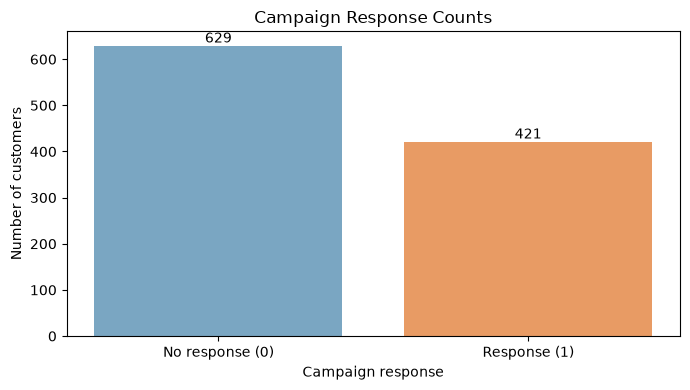

สัดส่วนคำตอบ (%):
 campaign_response
0    59.9
1    40.1
Name: proportion, dtype: float64


In [99]:
# กราฟที่ 1: ดูจำนวนและสัดส่วนของลูกค้าที่ตอบรับ/ไม่ตอบรับ
# pyplot ใช้สร้างกราฟและแสดงผลในโน้ตบุ๊ก
import matplotlib.pyplot as plt

# value_counts() นับจำนวนแต่ละค่าของ target; sort_index() เรียง 0 ก่อน 1
response_counts = df["campaign_response"].value_counts().sort_index()
# กำหนดป้ายแกน X ให้ตรงกับลำดับคำตอบ 0 และ 1
response_labels = ["No response (0)", "Response (1)"]

# สร้างพื้นที่วาดกราฟและกำหนดขนาดรูป
fig, ax = plt.subplots(figsize=(7, 4))
# bar() สร้างกราฟแท่ง โดยความสูงแทนจำนวนลูกค้าแต่ละกลุ่ม
bars = ax.bar(response_labels, response_counts.values, color=["#7aa6c2", "#e89b64"])
# ตั้งชื่อกราฟและชื่อแกนเพื่ออธิบายค่าที่แสดง
ax.set_title("Campaign Response Counts")
ax.set_xlabel("Campaign response")
ax.set_ylabel("Number of customers")
# ใส่จำนวนจริงไว้บนแท่งกราฟเพื่ออ่านค่าได้ง่าย
ax.bar_label(bars, fmt="%d")
# จัดระยะห่างไม่ให้ชื่อกราฟหรือชื่อแกนซ้อนกัน
fig.tight_layout()
# แสดงกราฟใน output ของเซลล์
plt.show()

# แสดงสัดส่วนเพื่อพิจารณาความสมดุลของข้อมูลเป้าหมาย
# normalize=True แปลงจำนวนเป็นสัดส่วน; คูณ 100 เพื่อรายงานเป็นเปอร์เซ็นต์
response_percent = (df["campaign_response"].value_counts(normalize=True).sort_index() * 100).round(1)
print("สัดส่วนคำตอบ (%):\n", response_percent)

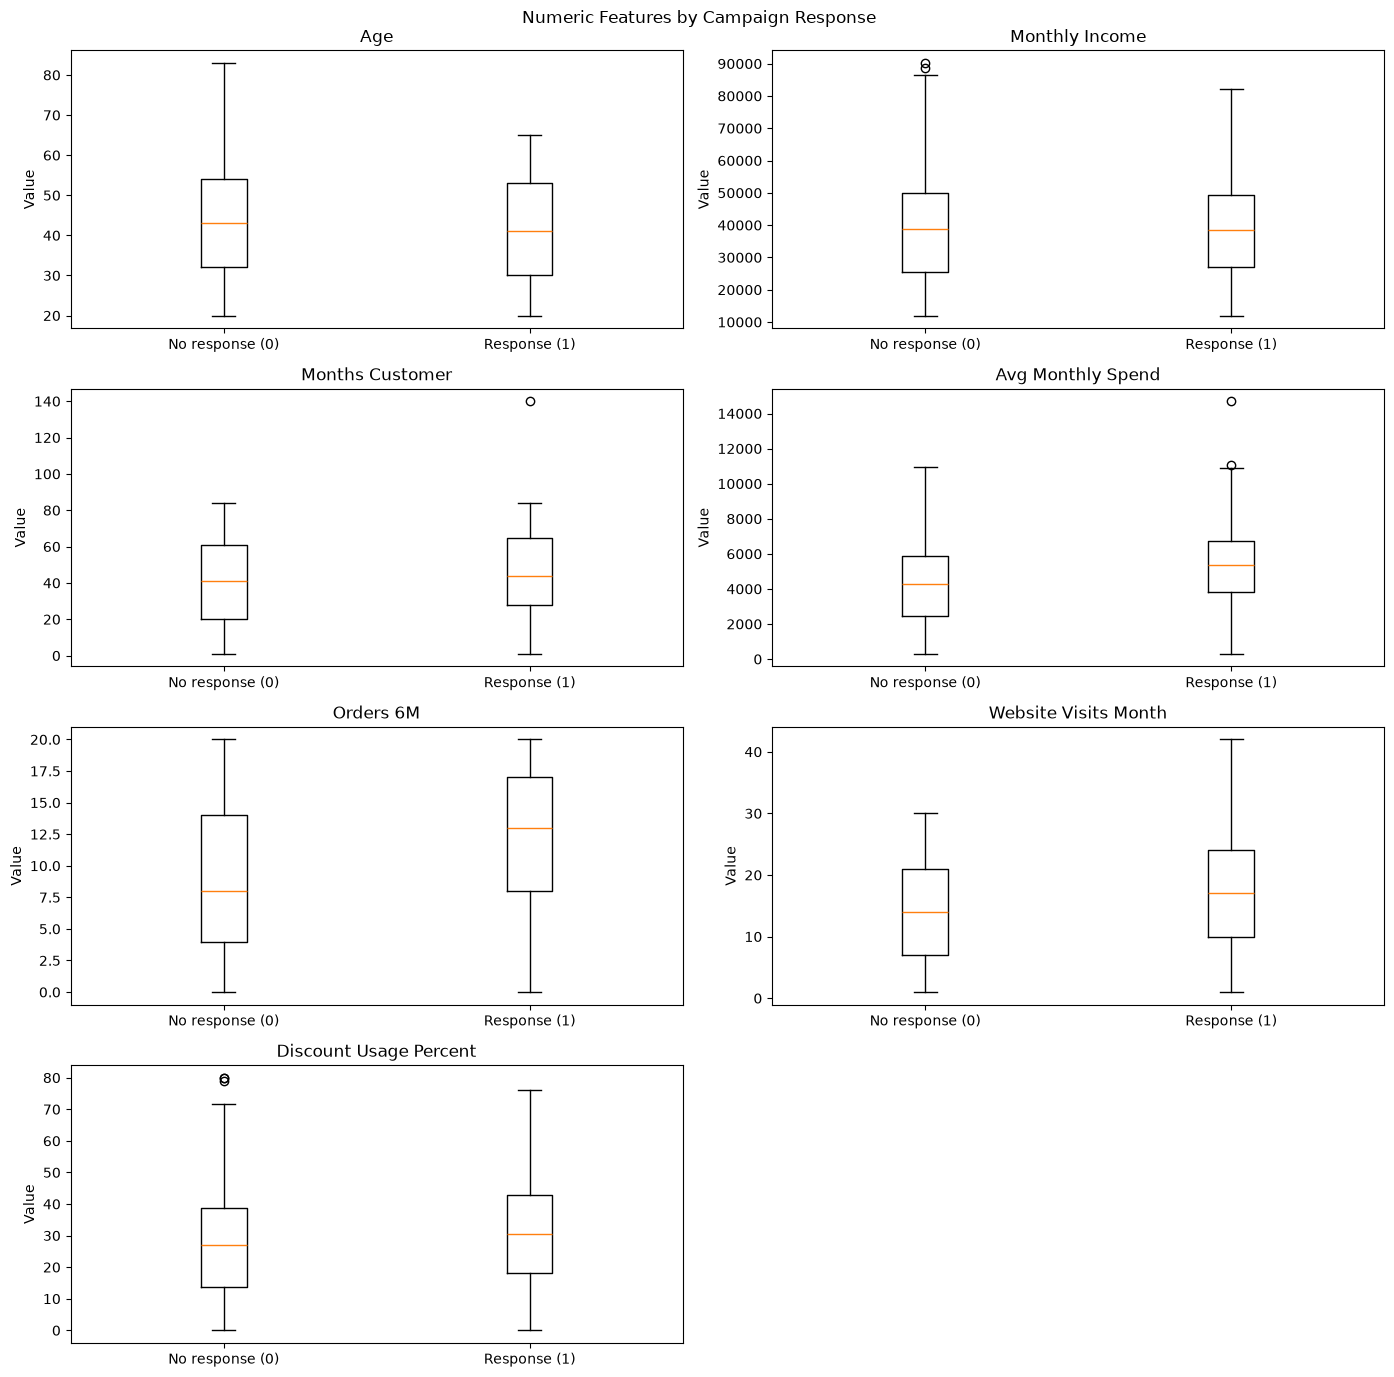

In [100]:
# กราฟที่ 2: เปรียบเทียบการกระจายของตัวแปรตัวเลขในสองกลุ่มคำตอบ
# เลือกตัวแปรเชิงตัวเลขที่ต้องการเปรียบเทียบระหว่าง target 0 และ 1
numeric_columns = [
    "age",
    "monthly_income",
    "months_customer",
    "avg_monthly_spend",
    "orders_6m",
    "website_visits_month",
    "discount_usage_percent",
]

# สร้างช่องกราฟ 8 ช่องสำหรับแสดง boxplot ของแต่ละตัวแปร
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
# วนสร้างกราฟทีละตัวแปรและจับคู่กับแกนของกราฟ
for column, ax in zip(numeric_columns, axes.flat):
# แยกค่าของตัวแปรตามกลุ่ม campaign_response 0 และ 1
    values_by_response = [
        df.loc[df["campaign_response"] == response, column]
        for response in [0, 1]
    ]
# boxplot ช่วยเทียบมัธยฐาน การกระจาย และค่าที่ห่างจากกลุ่ม
    ax.boxplot(values_by_response, tick_labels=["No response (0)", "Response (1)"])
# ตั้งชื่อกราฟย่อยตามชื่อตัวแปร
    ax.set_title(column.replace("_", " ").title())
    ax.set_ylabel("Value")

# ซ่อนช่องสุดท้ายเพราะมีตัวแปร 7 ตัว แต่สร้างพื้นที่ไว้ 8 ช่อง
axes.flat[-1].set_visible(False)
# ตั้งชื่อรวมให้กราฟชุดนี้
fig.suptitle("Numeric Features by Campaign Response")
# จัดระยะห่างของกราฟย่อย
fig.tight_layout()
# แสดงกราฟ boxplot ทั้งชุด
plt.show()

# เส้นกลางกล่องคือมัธยฐาน ส่วนกล่องและหนวดช่วยเปรียบเทียบการกระจายและค่าที่แตกต่าง

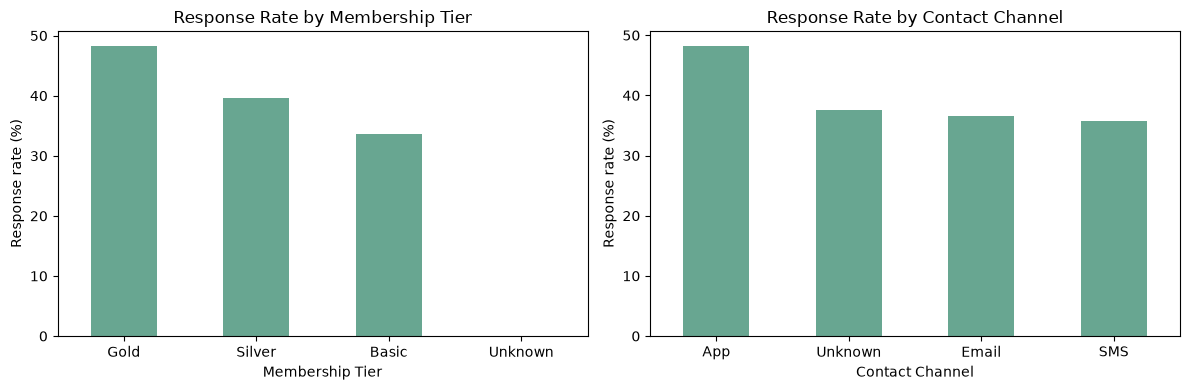

In [101]:
# กราฟที่ 3: เปรียบเทียบอัตราตอบรับของแต่ละระดับสมาชิกและช่องทางติดต่อ
# เลือกตัวแปรหมวดหมู่ที่จะตรวจความแตกต่างของอัตราตอบรับ
categorical_columns = ["membership_tier", "contact_channel"]
# สร้างกราฟ 2 ช่อง แยกตามตัวแปรหมวดหมู่
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# วนสร้างกราฟสำหรับแต่ละตัวแปรหมวดหมู่
for column, ax in zip(categorical_columns, axes):
# groupby() แบ่งข้อมูลตามหมวด; mean() ของ target 0/1 คูณ 100 คืออัตราตอบรับ
    response_rate = df.groupby(column, observed=False)["campaign_response"].mean() * 100
# เปลี่ยนป้ายค่าที่ไม่ระบุให้เป็น Unknown เพื่อให้อ่านกราฟได้ง่าย
    response_rate.index = response_rate.index.astype(str).str.replace("ไม่ระบุ", "Unknown", regex=False)
# เรียงหมวดหมู่จากอัตราตอบรับสูงไปต่ำก่อนวาดกราฟ
    response_rate.sort_values(ascending=False).plot(kind="bar", ax=ax, color="#68a691")
# ตั้งชื่อกราฟและแกนเพื่อระบุหมวดหมู่กับอัตราตอบรับ
    ax.set_title(f"Response Rate by {column.replace('_', ' ').title()}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Response rate (%)")
    ax.tick_params(axis="x", rotation=0)

# จัดระยะห่างของกราฟทั้งสองช่อง
fig.tight_layout()
# แสดงกราฟอัตราตอบรับ
plt.show()

# เนื่องจากคำตอบเป็น 0/1 ค่าเฉลี่ยของคำตอบในแต่ละกลุ่มคูณ 100 จึงเป็นอัตราตอบรับ (%)

### ตัวอย่างการแปลผลกราฟ EDA

- หลังลบแถวซ้ำ มีข้อมูล 1,050 แถว: ไม่ตอบรับ 629 ราย (59.9%) และตอบรับ 421 ราย (40.1%) จึงมีความไม่สมดุลอยู่บ้าง แต่ไม่ได้ห่างกันมาก
- จาก boxplot มัธยฐานของกลุ่มตอบรับสูงกว่าในยอดใช้จ่ายเฉลี่ยต่อเดือน (ประมาณ 5,369 เทียบกับ 4,277), จำนวนคำสั่งซื้อ (13 เทียบกับ 8), จำนวนเดือนที่เป็นลูกค้า (44 เทียบกับ 41) และจำนวนครั้งเข้าเว็บไซต์ (17 เทียบกับ 14) ส่วนรายได้ใกล้เคียงกัน (ประมาณ 38,488 และ 38,679)
- ในกราฟหมวดหมู่ กลุ่ม Gold มีอัตราตอบรับประมาณ 48.3% เทียบกับ Silver 39.7% และ Basic 33.6%; ช่องทาง App ประมาณ 48.2%, Email 36.6% และ SMS 35.8%

ตัวเลขเหล่านี้เป็นความสัมพันธ์เชิงพรรณนาจากข้อมูลชุดนี้ ไม่ได้แปลว่าตัวแปรนั้นเป็นสาเหตุ และกลุ่ม `Unknown` มีจำนวนน้อยจึงควรระวังในการตีความ

## Feature Selection, Train/Test Split และการเตรียมข้อมูล

กำหนด `campaign_response` เป็นเป้าหมาย และตัด `customer_id` ออกเพราะเป็นเพียงรหัสประจำตัว ไม่ใช่คุณลักษณะเชิงพฤติกรรม แบ่งชุดฝึก/ทดสอบก่อนเรียนรู้ค่าที่ใช้เติมข้อมูลและปรับสเกล เพื่อป้องกันข้อมูลรั่วไหล

ใช้ `OneHotEncoder` แปลงตัวแปรหมวดหมู่ และใช้ `StandardScaler` กับตัวเลขสำหรับ Logistic Regression ขั้นตอนเติมค่าว่าง/เอนโค้ด/ปรับสเกลจะเรียนรู้จากชุดฝึกเท่านั้น

In [102]:
# ขั้นที่ 1: แยกตัวแปรทำนาย (X) และเป้าหมาย (y); ไม่ใช้ customer_id เป็น feature
# X เก็บตัวแปรทำนายทั้งหมด ยกเว้น target และ customer_id
X = df_model_raw.drop(columns=["campaign_response", "customer_id"]).copy()
# y คือค่าคำตอบที่ต้องการให้โมเดลทำนาย โดยแปลงเป็นจำนวนเต็ม 0/1
y = df_model_raw["campaign_response"].astype(int)

# ทำชื่อหมวดหมู่ให้เป็นมาตรฐานด้วยกฎที่กำหนดไว้ และจัดค่าว่าง/ค่าที่ไม่รู้จักเป็น "ไม่ระบุ"
# กำหนดหมวดหมู่ที่ยอมรับและรูปแบบมาตรฐาน ไม่เรียนรู้หมวดจากชุดทดสอบ
category_mappings = {
    "membership_tier": {"basic": "Basic", "silver": "Silver", "gold": "Gold"},
    "contact_channel": {"sms": "SMS", "app": "App", "email": "Email"},
}
# ทำความสะอาดชื่อหมวดหมู่แต่ละคอลัมน์ก่อนแบ่งข้อมูล
for column, mapping in category_mappings.items():
# ตัดช่องว่างและทำตัวพิมพ์เล็กให้ชื่อหมวดหมู่เทียบกันได้
    normalized = X[column].astype("string").str.strip().str.casefold()
# map() จัดรูปแบบชื่อหมวด; fillna() แทนค่าว่าง/หมวดไม่รู้จัก
    X[column] = normalized.map(mapping).fillna("ไม่ระบุ")

# แบ่งข้อมูล 80% ฝึก และ 20% ทดสอบ โดยรักษาสัดส่วนคำตอบ 0/1
from sklearn.model_selection import train_test_split

# กันข้อมูลทดสอบไว้ประเมินโมเดล ไม่ใช้ฝึกหรือเรียนรู้ preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# เลือกคอลัมน์ตามชนิดข้อมูล เพื่อส่งเข้า preprocessing ที่เหมาะสม
# เลือกชื่อคอลัมน์ตัวเลขสำหรับ pipeline ที่เติมค่ามัธยฐานและปรับสเกล
numeric_features = X_train.select_dtypes(include="number").columns
# เลือกชื่อคอลัมน์หมวดหมู่สำหรับ pipeline ที่เติมค่าและ One-Hot Encode
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns

# พิมพ์รายการคอลัมน์และขนาดชุดข้อมูลเพื่อตรวจสอบขั้นตอนแบ่งข้อมูล
print("Features (ไม่รวม customer_id และ target):", list(X.columns))
print("คอลัมน์ตัวเลข:", list(numeric_features))
print("คอลัมน์หมวดหมู่:", list(categorical_features))
print("จำนวนแถวชุดฝึก:", len(X_train))
print("จำนวนแถวชุดทดสอบ:", len(X_test))

Features (ไม่รวม customer_id และ target): ['age', 'monthly_income', 'months_customer', 'avg_monthly_spend', 'orders_6m', 'website_visits_month', 'discount_usage_percent', 'membership_tier', 'contact_channel']
คอลัมน์ตัวเลข: ['age', 'monthly_income', 'months_customer', 'avg_monthly_spend', 'orders_6m', 'website_visits_month', 'discount_usage_percent']
คอลัมน์หมวดหมู่: ['membership_tier', 'contact_channel']
จำนวนแถวชุดฝึก: 840
จำนวนแถวชุดทดสอบ: 210


In [103]:
# ขั้นที่ 2: เติมค่าว่าง เอนโค้ดหมวดหมู่ และปรับสเกลตัวเลข
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Pipeline ตัวเลข: เติมค่าว่างด้วยมัธยฐาน แล้วปรับสเกลให้เหมาะกับ Logistic Regression
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
# Pipeline หมวดหมู่: เติมค่าที่พบบ่อย แล้วเข้ารหัสแต่ละหมวดเป็น 0/1
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
# เลือกใช้ pipeline ให้ตรงชนิดคอลัมน์; การ fit จะเกิดภายหลังจากแบ่งข้อมูลแล้ว
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# แจ้งว่าแต่ละโมเดลจะ fit ตัวเตรียมข้อมูลจากชุดฝึกเท่านั้น
print("การเตรียมข้อมูลจะถูก fit ภายในแต่ละโมเดลด้วย X_train เท่านั้น")

การเตรียมข้อมูลจะถูก fit ภายในแต่ละโมเดลด้วย X_train เท่านั้น


## เปรียบเทียบโมเดล Classification และประเมินผล

เปรียบเทียบ Logistic Regression กับ Random Forest บนชุดทดสอบชุดเดียวกัน

- **Accuracy**: สัดส่วนคำทำนายถูกทั้งหมด
- **Precision (class 1)**: ในกลุ่มที่โมเดลทำนายว่าตอบรับ มีสัดส่วนที่ตอบรับจริงเท่าใด
- **Recall (class 1)**: ในกลุ่มที่ตอบรับจริง โมเดลตรวจพบได้เท่าใด
- **F1-score (class 1)**: ค่าเฉลี่ยฮาร์มอนิกของ Precision และ Recall
- **Confusion Matrix**: แสดงจำนวนทำนายถูก/ผิด แถวคือค่าจริง คอลัมน์คือค่าที่โมเดลทำนาย; สำหรับคลาส 1 ช่อง false negative คือผู้ตอบรับจริงที่โมเดลพลาด

เลือกโมเดลจาก metric ที่สอดคล้องกับเป้าหมาย ไม่ควรสรุปจาก Accuracy เพียงค่าเดียว

In [104]:
# ขั้นที่ 3: ฝึกสองโมเดลด้วยชุดฝึก และประเมินด้วยชุดทดสอบ
# clone() สร้างตัวเตรียมข้อมูลใหม่ให้แต่ละโมเดลเริ่ม fit จากสถานะสะอาด
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# กำหนดโมเดลสองชนิดเพื่อเปรียบเทียบด้วยชุดฝึก/ทดสอบชุดเดียวกัน
models = {
# Logistic Regression เป็น baseline เชิงเส้นสำหรับจำแนกคำตอบ 0/1
    "Logistic Regression": LogisticRegression(max_iter=1000),
# Random Forest รวมต้นไม้หลายต้น; balanced ช่วยคำนึงถึงสัดส่วนคลาส
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
    ),
}

# เตรียมเก็บ metric ของแต่ละโมเดลและ confusion matrix
results = []
confusion_matrices = {}
# ฝึกและประเมินโมเดลแต่ละตัวด้วยขั้นตอนเดียวกัน
for model_name, classifier in models.items():
    # Pipeline จะ fit preprocessing จากชุดฝึก แล้วใช้แปลงชุดทดสอบโดยไม่เรียนรู้ซ้ำ
# รวมการเติมค่าว่าง/เข้ารหัส/ปรับสเกลกับตัวจำแนกเป็นขั้นตอนเดียว
    model_pipeline = Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", classifier),
    ])
# fit เรียนรู้ preprocessing และพารามิเตอร์โมเดลจากชุดฝึกเท่านั้น
    model_pipeline.fit(X_train, y_train)
# ใช้โมเดลที่ฝึกแล้วทำนายชุดทดสอบที่กันไว้
    predictions = model_pipeline.predict(X_test)

# คำนวณ Accuracy, Precision, Recall และ F1 สำหรับคลาส 1 (ตอบรับ)
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (class 1)": precision_score(y_test, predictions, pos_label=1, zero_division=0),
        "Recall (class 1)": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "F1 (class 1)": f1_score(y_test, predictions, pos_label=1, zero_division=0),
    })
# labels=[0, 1] กำหนดลำดับแถว/คอลัมน์ให้ตรงกับคลาสไม่ตอบรับและตอบรับ
    confusion_matrices[model_name] = confusion_matrix(y_test, predictions, labels=[0, 1])

# รวม metric เป็นตารางและเรียงจาก F1 คลาส 1 สูงไปต่ำ
results_df = pd.DataFrame(results).set_index("Model").sort_values("F1 (class 1)", ascending=False)
print("เปรียบเทียบผลบนชุดทดสอบ:")
print(results_df.round(3))

# แสดง confusion matrix ของแต่ละโมเดลเพื่อเห็นจำนวนทำนายถูก/ผิด
for model_name, matrix in confusion_matrices.items():
    print(f"\nConfusion Matrix - {model_name} (แถว=ค่าจริง, คอลัมน์=ค่าทำนาย):")
# แถวของ matrix คือค่าจริง ส่วนคอลัมน์คือค่าที่ทำนาย
    print(pd.DataFrame(
        matrix,
        index=["Actual: No response (0)", "Actual: Response (1)"],
        columns=["Predicted: No response (0)", "Predicted: Response (1)"],
    ))

เปรียบเทียบผลบนชุดทดสอบ:
                     Accuracy  Precision (class 1)  Recall (class 1)  \
Model                                                                  
Logistic Regression     0.662                0.578             0.571   
Random Forest           0.610                0.510             0.595   

                     F1 (class 1)  
Model                              
Logistic Regression         0.575  
Random Forest               0.549  

Confusion Matrix - Logistic Regression (แถว=ค่าจริง, คอลัมน์=ค่าทำนาย):
                         Predicted: No response (0)  Predicted: Response (1)
Actual: No response (0)                          91                       35
Actual: Response (1)                             36                       48

Confusion Matrix - Random Forest (แถว=ค่าจริง, คอลัมน์=ค่าทำนาย):
                         Predicted: No response (0)  Predicted: Response (1)
Actual: No response (0)                          78                       48
Actual: Response 

## ปรับ Logistic Regression ด้วย Cross-Validation

ค้นหาค่า `C` และ `class_weight` ด้วย Stratified 5-fold cross-validation บนชุดฝึก โดยใช้ Accuracy เป็นคะแนนหลัก จากนั้นประเมินโมเดลที่เลือกบนชุดทดสอบที่กันไว้เพียงครั้งเดียว พร้อมรายงาน Precision, Recall, F1-score และ Confusion Matrix เพื่อดูผลต่อคลาสที่ตอบรับด้วย

In [105]:
# ปรับพารามิเตอร์ด้วยชุดฝึกเท่านั้น; preprocessing จะถูก fit ใหม่ในแต่ละ fold
from sklearn.model_selection import GridSearchCV, StratifiedKFold

tuned_logistic_pipeline = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000)),
])

logistic_search = GridSearchCV(
    estimator=tuned_logistic_pipeline,
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
logistic_search.fit(X_train, y_train)

print("พารามิเตอร์ที่ดีที่สุด:", logistic_search.best_params_)
print(f"Accuracy เฉลี่ยจาก 5-fold CV: {logistic_search.best_score_:.3f}")

# ประเมินบน test ที่ไม่ได้ใช้เลือกรุ่นหรือพารามิเตอร์
tuned_predictions = logistic_search.best_estimator_.predict(X_test)
tuned_result = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision (class 1)": precision_score(y_test, tuned_predictions, pos_label=1, zero_division=0),
    "Recall (class 1)": recall_score(y_test, tuned_predictions, pos_label=1, zero_division=0),
    "F1 (class 1)": f1_score(y_test, tuned_predictions, pos_label=1, zero_division=0),
}
comparison_with_tuned = pd.concat([
    results_df,
    pd.DataFrame([tuned_result]).set_index("Model"),
]).sort_values("F1 (class 1)", ascending=False)
print("\nเปรียบเทียบผลบนชุดทดสอบ (รวม Logistic Regression ที่ปรับแล้ว):")
print(comparison_with_tuned.round(3))

tuned_matrix = confusion_matrix(y_test, tuned_predictions, labels=[0, 1])
print("\nConfusion Matrix - Tuned Logistic Regression (แถว=ค่าจริง, คอลัมน์=ค่าทำนาย):")
print(pd.DataFrame(
    tuned_matrix,
    index=["Actual: No response (0)", "Actual: Response (1)"],
    columns=["Predicted: No response (0)", "Predicted: Response (1)"],
))

พารามิเตอร์ที่ดีที่สุด: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Accuracy เฉลี่ยจาก 5-fold CV: 0.676

เปรียบเทียบผลบนชุดทดสอบ (รวม Logistic Regression ที่ปรับแล้ว):
                           Accuracy  Precision (class 1)  Recall (class 1)  \
Model                                                                        
Tuned Logistic Regression     0.624                0.523             0.690   
Logistic Regression           0.662                0.578             0.571   
Random Forest                 0.610                0.510             0.595   

                           F1 (class 1)  
Model                                    
Tuned Logistic Regression         0.595  
Logistic Regression               0.575  
Random Forest                     0.549  

Confusion Matrix - Tuned Logistic Regression (แถว=ค่าจริง, คอลัมน์=ค่าทำนาย):
                         Predicted: No response (0)  Predicted: Response (1)
Actual: No response (0)                          73       

## ทดลองโมเดลอื่นที่จับความสัมพันธ์ไม่เป็นเส้นตรง

เปรียบเทียบ Random Forest, Extra Trees และ SVM (RBF) ด้วย Stratified 5-fold cross-validation บนชุดฝึก เลือกจาก Accuracy เฉลี่ย แล้วประเมินโมเดลที่ชนะบนชุดทดสอบชุดเดิมเพียงครั้งเดียว การเปรียบเทียบนี้ช่วยดูว่าโมเดลแบบไม่เชิงเส้นเหมาะกับข้อมูลมากกว่า Logistic Regression หรือไม่

In [106]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.svm import SVC

nonlinear_pipeline = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(random_state=42)),
])
nonlinear_param_grid = [
    {
        "classifier": [RandomForestClassifier(random_state=42, class_weight="balanced")],
        "classifier__n_estimators": [200, 400],
        "classifier__max_features": ["sqrt", 0.8],
        "classifier__min_samples_leaf": [1, 3],
    },
    {
        "classifier": [ExtraTreesClassifier(random_state=42, class_weight="balanced")],
        "classifier__n_estimators": [200, 400],
        "classifier__max_features": ["sqrt", 0.8],
        "classifier__min_samples_leaf": [1, 3],
    },
    {
        "classifier": [SVC()],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", "auto"],
        "classifier__class_weight": [None, "balanced"],
    },
]

nonlinear_search = GridSearchCV(
    estimator=nonlinear_pipeline,
    param_grid=nonlinear_param_grid,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
nonlinear_search.fit(X_train, y_train)
print("โมเดล/พารามิเตอร์ที่ดีที่สุดจาก CV:", nonlinear_search.best_params_)
print(f"Accuracy เฉลี่ยจาก 5-fold CV: {nonlinear_search.best_score_:.3f}")

# ประเมินผู้ชนะจาก CV บนชุดทดสอบที่กันไว้
nonlinear_predictions = nonlinear_search.best_estimator_.predict(X_test)
nonlinear_result = {
    "Model": f"Tuned {type(nonlinear_search.best_estimator_.named_steps['classifier']).__name__}",
    "Accuracy": accuracy_score(y_test, nonlinear_predictions),
    "Precision (class 1)": precision_score(y_test, nonlinear_predictions, pos_label=1, zero_division=0),
    "Recall (class 1)": recall_score(y_test, nonlinear_predictions, pos_label=1, zero_division=0),
    "F1 (class 1)": f1_score(y_test, nonlinear_predictions, pos_label=1, zero_division=0),
}
all_model_results = pd.concat([
    comparison_with_tuned,
    pd.DataFrame([nonlinear_result]).set_index("Model"),
]).sort_values("Accuracy", ascending=False)
print("\nเปรียบเทียบ Accuracy บนชุดทดสอบ:")
print(all_model_results.round(3))

nonlinear_matrix = confusion_matrix(y_test, nonlinear_predictions, labels=[0, 1])
print("\nConfusion Matrix - โมเดลไม่เชิงเส้นที่ชนะจาก CV:")
print(pd.DataFrame(
    nonlinear_matrix,
    index=["Actual: No response (0)", "Actual: Response (1)"],
    columns=["Predicted: No response (0)", "Predicted: Response (1)"],
))

โมเดล/พารามิเตอร์ที่ดีที่สุดจาก CV: {'classifier': SVC(), 'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'auto'}
Accuracy เฉลี่ยจาก 5-fold CV: 0.651

เปรียบเทียบ Accuracy บนชุดทดสอบ:
                           Accuracy  Precision (class 1)  Recall (class 1)  \
Model                                                                        
Logistic Regression           0.662                0.578             0.571   
Tuned SVC                     0.643                0.540             0.726   
Tuned Logistic Regression     0.624                0.523             0.690   
Random Forest                 0.610                0.510             0.595   

                           F1 (class 1)  
Model                                    
Logistic Regression               0.575  
Tuned SVC                         0.619  
Tuned Logistic Regression         0.595  
Random Forest                     0.549  

Confusion Matrix - โมเดลไม่เชิงเส้นที่ชนะจาก CV:
          

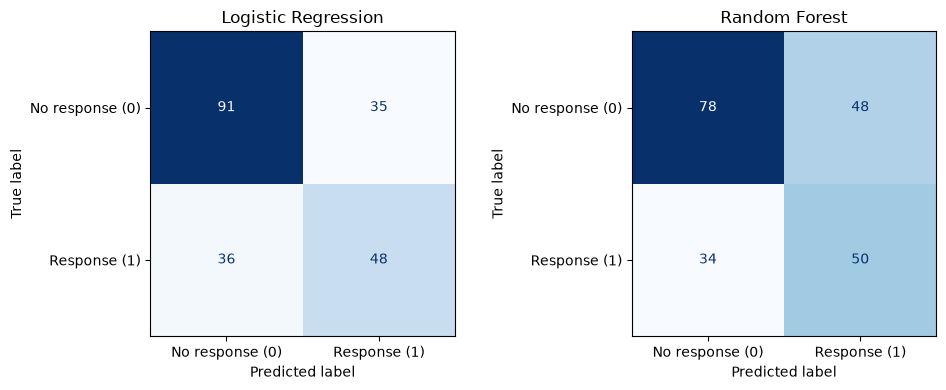

In [107]:
# แสดง confusion matrix ของทั้งสองโมเดลเพื่อเปรียบเทียบรูปแบบความผิดพลาด
# ConfusionMatrixDisplay แสดงตารางความผิดพลาดเป็นภาพ
from sklearn.metrics import ConfusionMatrixDisplay

# สร้างพื้นที่กราฟสำหรับแสดง confusion matrix ของแต่ละโมเดล
fig, axes = plt.subplots(1, len(confusion_matrices), figsize=(10, 4))
# วนวาด matrix ที่คำนวณไว้สำหรับแต่ละโมเดล
for ax, (model_name, matrix) in zip(axes, confusion_matrices.items()):
# กำหนด matrix และชื่อคลาสให้แกนอ่านเข้าใจ
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["No response (0)", "Response (1)"],
    )
# วาดค่าจำนวนจริงในแต่ละช่องด้วยสีเพื่อช่วยเปรียบเทียบ
    display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name)

# จัดระยะห่างไม่ให้กราฟทั้งสองซ้อนกัน
fig.tight_layout()
# แสดง confusion matrix ของโมเดลทั้งหมด
plt.show()

### สรุปและแปลผลการเปรียบเทียบ

เมื่อรันด้วย `random_state=42` ผลชุดทดสอบที่ได้คือ Logistic Regression มี Accuracy 0.662, Precision (class 1) 0.578, Recall (class 1) 0.571 และ F1 0.575 ส่วน Random Forest ได้ 0.610, 0.510, 0.595 และ 0.549 ตามลำดับ

ดังนั้น Logistic Regression ทำได้ดีกว่าใน Accuracy, Precision และ F1 ในการแบ่งข้อมูลครั้งนี้ ขณะที่ Random Forest ตรวจพบลูกค้าที่ตอบรับได้มากกว่าเล็กน้อยจาก Recall (0.595 เทียบกับ 0.571) หากเป้าหมายคือพลาดผู้ตอบรับให้น้อยลงให้พิจารณา Recall; หากต้องการสมดุล Precision/Recall ให้พิจารณา F1 ด้วย ทั้งนี้ผลยังเป็น baseline จากการแบ่งข้อมูลชุดเดียว ควรทดลองและตรวจสอบเพิ่มเติมก่อนนำไปใช้งานจริง

## Clustering: เปรียบเทียบ K-Means กับ Agglomerative Clustering

การจัดกลุ่มนี้ใช้คุณลักษณะลูกค้าโดยไม่ใช้ `customer_id` และ `campaign_response` ในการสร้างกลุ่ม ปรับสเกลตัวเลขและ One-Hot Encode หมวดหมู่ด้วย preprocessing เดิม ทดลองจำนวนกลุ่ม 2-6 แล้วเลือกจำนวนที่มี Silhouette Score สูงสุดของแต่ละวิธี คะแนนยิ่งสูงโดยทั่วไปหมายถึงกลุ่มแยกจากกันและเกาะกลุ่มภายในได้ดีขึ้น ส่วนอัตราตอบรับของแต่ละกลุ่มแสดงภายหลังเพื่อช่วยตีความเท่านั้น ไม่ได้ใช้ฝึกหรือเลือกกลุ่ม

In [108]:
from scipy import sparse
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score

# X ไม่มี customer_id และ campaign_response; transform fit กับ feature เท่านั้น
clustering_preprocessor = clone(preprocessor)
X_cluster = clustering_preprocessor.fit_transform(X)
if sparse.issparse(X_cluster):
    X_cluster = X_cluster.toarray()

cluster_counts = range(2, 7)
silhouette_sample_size = min(1000, len(X_cluster))
clustering_results = []
best_cluster_labels = {}
best_cluster_scores = {}

for model_name in ["K-Means", "Agglomerative"]:
    for n_clusters in cluster_counts:
        if model_name == "K-Means":
            cluster_model = KMeans(
                n_clusters=n_clusters,
                n_init=20,
                random_state=42,
            )
        else:
            cluster_model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage="ward",
            )

        cluster_labels = cluster_model.fit_predict(X_cluster)
        score = silhouette_score(
            X_cluster,
            cluster_labels,
            sample_size=silhouette_sample_size,
            random_state=42,
        )
        clustering_results.append({
            "Model": model_name,
            "Number of clusters": n_clusters,
            "Silhouette Score": score,
        })
        if score > best_cluster_scores.get(model_name, float("-inf")):
            best_cluster_scores[model_name] = score
            best_cluster_labels[model_name] = cluster_labels

clustering_results_df = pd.DataFrame(clustering_results)
best_clustering_results = (
    clustering_results_df.sort_values("Silhouette Score", ascending=False)
    .groupby("Model", sort=False)
    .head(1)
    .sort_values("Silhouette Score", ascending=False)
    .reset_index(drop=True)
)
print("ผลการทดลองทุกจำนวนกลุ่ม:")
print(clustering_results_df.pivot(
    index="Number of clusters",
    columns="Model",
    values="Silhouette Score",
).round(3))
print("\nโมเดลและจำนวนกลุ่มที่ดีที่สุดของแต่ละวิธี:")
print(best_clustering_results.round(3))

# แสดงจำนวนลูกค้าและอัตราตอบรับรายกลุ่มเพื่อช่วยอธิบายผลเท่านั้น
for model_name, cluster_labels in best_cluster_labels.items():
    cluster_profile = pd.DataFrame({
        "cluster": cluster_labels,
        "campaign_response": y.to_numpy(),
    }).groupby("cluster").agg(
        customers=("campaign_response", "size"),
        response_rate=("campaign_response", "mean"),
    )
    cluster_profile["response_rate"] *= 100
    print(f"\nโปรไฟล์กลุ่ม {model_name} (response rate ใช้ตีความหลังจัดกลุ่ม):")
    print(cluster_profile.round(1))

ผลการทดลองทุกจำนวนกลุ่ม:
Model               Agglomerative  K-Means
Number of clusters                        
2                           0.060    0.090
3                           0.045    0.082
4                           0.037    0.086
5                           0.036    0.087
6                           0.036    0.086

โมเดลและจำนวนกลุ่มที่ดีที่สุดของแต่ละวิธี:
           Model  Number of clusters  Silhouette Score
0        K-Means                   2              0.09
1  Agglomerative                   2              0.06

โปรไฟล์กลุ่ม K-Means (response rate ใช้ตีความหลังจัดกลุ่ม):
         customers  response_rate
cluster                          
0              535           31.2
1              515           49.3

โปรไฟล์กลุ่ม Agglomerative (response rate ใช้ตีความหลังจัดกลุ่ม):
         customers  response_rate
cluster                          
0              677           49.8
1              373           22.5


### คำอธิบายผล Clustering

จากการทดลองนี้ K-Means ได้ Silhouette Score สูงสุดที่ประมาณ 0.090 เมื่อแบ่งเป็น 2 กลุ่ม ส่วน Agglomerative Clustering ได้ประมาณ 0.060 เมื่อแบ่งเป็น 2 กลุ่มเช่นกัน K-Means จึงแยกกลุ่มได้ดีกว่าเล็กน้อยตามเกณฑ์นี้ แต่คะแนนของทั้งคู่ค่อนข้างต่ำ แสดงว่าข้อมูลของลูกค้าแต่ละกลุ่มยังทับซ้อนกันมากและยังไม่มีเส้นแบ่งที่ชัดเจน ไม่ควรตีความว่าการแบ่งกลุ่มมีคุณภาพสูง

โปรไฟล์ของ K-Means มีลูกค้า 535 และ 515 ราย โดยอัตราตอบรับอยู่ที่ประมาณ 31.2% และ 49.3% ตามลำดับ ส่วน Agglomerative มี 677 และ 373 ราย อัตราตอบรับประมาณ 49.8% และ 22.5% ตัวเลขอัตราตอบรับนำมาแสดงหลังจากจัดกลุ่มแล้วเพื่อช่วยอธิบายลักษณะกลุ่มเท่านั้น ไม่ได้ใช้สร้างกลุ่มหรือเลือกโมเดล ดังนั้นยังสรุปไม่ได้ว่ากลุ่มใดจะตอบรับแคมเปญในอนาคตแน่นอน

Silhouette Score วัดความใกล้กันของข้อมูลภายในกลุ่มเทียบกับความห่างจากกลุ่มอื่น และไม่ใช่ Accuracy เพราะ Clustering ไม่มีป้ายกำกับคำตอบที่ถูกต้อง ควรใช้ผลนี้เป็นการแบ่งกลุ่มลูกค้าเบื้องต้น และพิจารณาความหมายของคุณลักษณะลูกค้าในแต่ละกลุ่มก่อนนำไปใช้